## Developing a better forecast of returns 15:50 - 16:00pm

### Collecting Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(21,0)))
    .with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11)
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
# daily volume before the final 10mins
# session_dollar_volume = (
#     df_trades
#     .select((["ts_event", "symbol", "price", "size"]))
#     .with_columns(pl.col("ts_event").dt.date().alias("date"))
#     .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(15,50)))
#     .group_by(["date", "symbol"])
#     .agg(
#     (pl.col('size') * pl.col("price")).sum().alias("SDV")
#     )
#     .sort("date")
#     .collect(engine="streaming")
# )

avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).over("symbol").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
    .collect(engine="streaming")
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (
            (pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2)
        ).alias("spread_return")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["price", "spread_return"]).last()
    )
    .rename({"price":"entry_price"})
    .collect(engine="streaming")
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty"]).first()
    )
    .collect(engine="streaming")
)

In [7]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    # .join(session_dollar_volume, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .with_columns((pl.col("total_imbalance_qty") * pl.col("entry_price")).alias("dollar_imbalance"))
    .drop(["total_imbalance_qty"])
    .drop_nulls()
    .with_columns(
        # (
        #     pl.when(pl.col("side") == "B").then(1)
        #     .when(pl.col("side") == "A").then(-1)
        #     .when(pl.col("side") == "N").then(0)
        #     *(pl.col("dollar_imbalance") / pl.col("SDV"))
        # ).alias("signed_session_imb_ratio"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("ADV"))
        ).alias("signed_mean_imb_ratio"),
        (
            pl.col("dollar_imbalance") / pl.col("dollar_imbalance").sum().over(pl.col("date"))
        ).alias("pct_total_dollar_imb"),
        (
            (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("return_to_close")
    )
)

# The dataframe we will be working with
data

date,symbol,side,entry_price,spread_return,auction_price,ADV,dollar_imbalance,signed_mean_imb_ratio,pct_total_dollar_imb,return_to_close
date,cat,str,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-11,"""AAL""","""A""",11.035,0.000906,11.06,9.7183e7,1.4006e6,-0.014412,0.000572,0.002266
2025-06-11,"""AAOI""","""B""",16.37,0.001221,16.32,1.4384e7,208340.99,0.014484,0.000085,-0.003054
2025-06-11,"""AAON""","""B""",75.78,0.001056,75.85,4.9410e7,565849.26,0.011452,0.000231,0.000924
2025-06-11,"""AAPL""","""A""",198.81,0.000201,198.78,2.2199e9,5.4598e7,-0.024595,0.02231,-0.000151
2025-06-11,"""AAXJ""","""N""",81.8,0.000122,81.88,2.4416e7,0.0,0.0,0.0,0.000978
…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""ZG""","""N""",34.46,0.00029,34.1,1.4582e7,0.0,0.0,0.0,-0.010447
2026-06-10,"""ZION""","""N""",65.56,0.000305,65.82,2.7290e7,0.0,0.0,0.0,0.003966
2026-06-10,"""ZLAB""","""A""",17.3,0.000578,17.26,4.5611e6,1192938.8,-0.261546,0.000245,-0.002312


### Working on Forecasting

In [23]:
import sklearn
import statsmodels.api as sm

features = ["signed_mean_imb_ratio", "pct_total_dollar_imb"]

X = data[features].to_pandas()
y = data["return_to_close"].to_pandas()

model = sklearn.linear_model.LinearRegression()
model.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [24]:
print("Model coefficients:\n")
for i, f in enumerate(features):
    print(f, "=", model.coef_[i].round(5))

Model coefficients:

signed_mean_imb_ratio = 0.0027
pct_total_dollar_imb = -0.00031


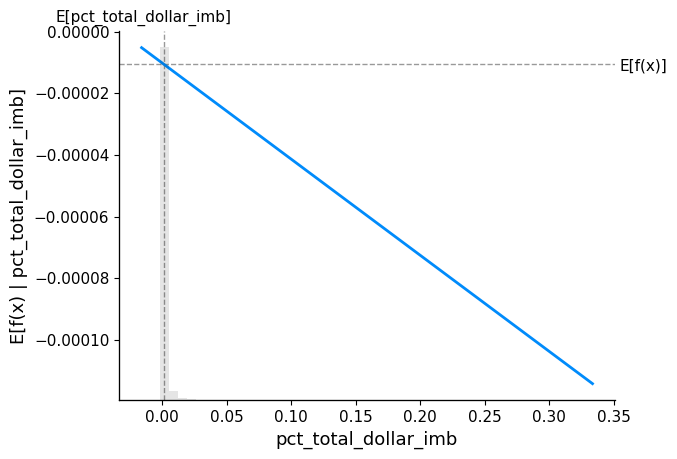

In [26]:
import shap

shap.partial_dependence_plot(
    "pct_total_dollar_imb",
    model.predict,
    X,
    ice=False,
    model_expected_value=True,
    feature_expected_value=True,
)

Background dataset has 214547 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=214547 when initializing the masker.
ExactExplainer explainer: 214548it [01:55, 1701.87it/s]                            


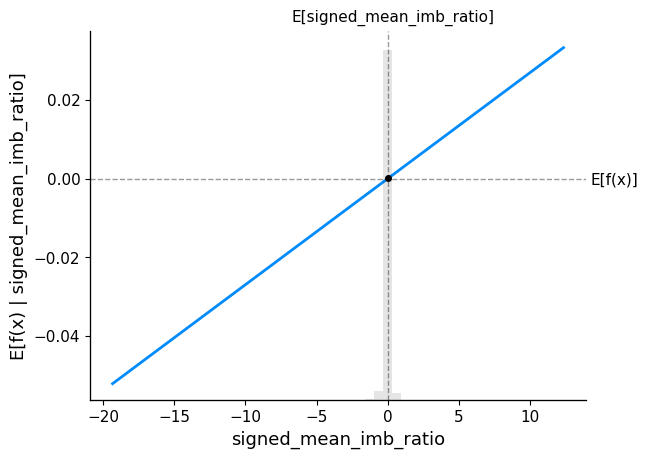

In [27]:
# compute the SHAP values for the linear model
explainer = shap.Explainer(model.predict, X)
shap_values = explainer(X)

# make a standard partial dependence plot
sample_ind = 20
shap.partial_dependence_plot(
    "signed_mean_imb_ratio",
    model.predict,
    X,
    model_expected_value=True,
    feature_expected_value=True,
    ice=False,
    shap_values=shap_values[sample_ind : sample_ind + 1, :],
)

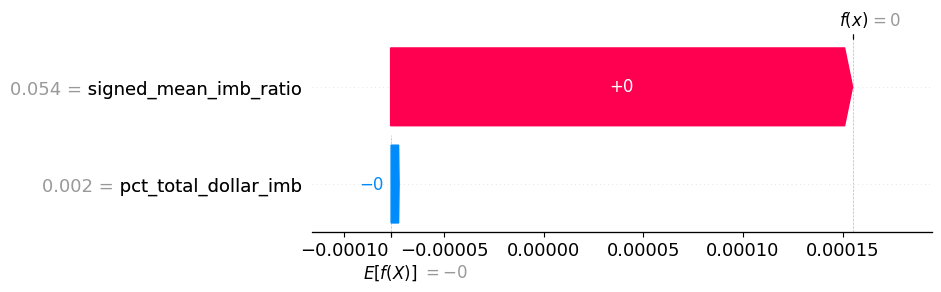

In [29]:
shap.plots.waterfall(shap_values[sample_ind])
